In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\asus\Downloads\final_cleaned_data.csv")

In [3]:
df["Date"] = pd.to_datetime(df["Date"])
df["Duration_hours"] = pd.to_timedelta(df["Duration_hours"])
df["Delay_minutes"] = pd.to_timedelta(df["Delay_minutes"])

In [4]:
def sec_count(qw,a):
    li=[]
    res=[]
    i=0
    while i<a:
        if len(li)==0:
            res.append(f"{i}-{i,i+600}")
            li.append((i,i+600))
            i+=600
        elif len(li)==1:
            li.append((i,i+1200))
            res.append(f"{i}-{i+1200}")
            i+=1200
        else:
            li.append((i,i+1800))
            res.append(f"{i}-{i+1800}")
            i+=1800
    return {j: len(list(filter(lambda x: x>=i[0] and x<i[1],qw))) for i,j in zip(li,res)}

In [5]:
df.isna().sum()

Flight_Number        0
Airline              0
Aircraft_Type        0
Origin               0
Destination          0
Date                 0
Distance_km          0
Duration_hours       0
Ticket_Price         0
Fuel_Cost            0
Weather_Condition    0
Delay_minutes        0
Passenger_Count      0
dtype: int64

In [6]:
df

,Flight_Number,Airline,Aircraft_Type,Origin,Destination,Date,Distance_km,Duration_hours,Ticket_Price,Fuel_Cost,Weather_Condition,Delay_minutes,Passenger_Count
0,8498,SpiceJet,ATR72,CCU,MAA,2023-06-12,1384.0,0 days 03:05:42,2963.516704,3828.490167,Cloudy,0 days 00:00:00,62
1,5263,IndiGo,A320,AMD,PNQ,2023-09-21,519.0,0 days 01:06:27,2912.486246,1790.502002,Cloudy,0 days 00:27:55,119
2,1877,GoAir,B737,CCU,DEL,2023-11-30,1423.0,0 days 02:06:45,2177.869901,5122.704201,Cloudy,0 days 00:26:20,122
3,1598,GoAir,B737,AMD,HYD,2023-06-30,907.0,0 days 01:30:56,2204.381503,3289.369504,Cloudy,0 days 00:13:46,143
4,2722,GoAir,ATR72,HYD,PNQ,2023-10-24,529.0,0 days 01:43:03,2321.112931,1543.099700,Clear,0 days 00:18:55,40
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2098,GoAir,A321,CCU,AMD,2023-12-06,1753.0,0 days 02:31:52,2995.180173,6435.115093,Clear,0 days 00:07:44,195
99996,1978,GoAir,A321,AMD,PNQ,2023-07-21,519.0,0 days 01:08:14,2971.397586,2030.405612,Clear,0 days 00:03:34,158
99997,7474,Air India,A320,DEL,DEL,2023-08-29,0.0,0 days 00:30:00,3380.840213,500.000000,Clear,0 days 00:00:00,93
99998,2248,IndiGo,B777,MAA,PNQ,2023-07-17,933.0,0 days 01:25:30,3542.425616,3908.780885,Rainy,0 days 00:27:58,243


In [7]:
#df[df["Distance_km"]==0].groupby("Airline")["Flight_Number"].count()
df[df["Distance_km"]==0]["Airline"].value_counts()

Airline
Air India    2569
Vistara      2562
SpiceJet     2539
IndiGo       2516
GoAir        2461
Name: count, dtype: int64

In [8]:
can=df[df["Distance_km"]==0]["Airline"].value_counts()
dep=df[df["Distance_km"]!=0]["Airline"].value_counts()
pd.DataFrame(dep).reset_index()
pd.DataFrame(can).reset_index()
pd.merge(pd.DataFrame(dep).reset_index(),pd.DataFrame(can).reset_index(), how="inner", on="Airline")

,Airline,count_x,count_y
0,Air India,17655,2569
1,GoAir,17513,2461
2,IndiGo,17446,2516
3,Vistara,17371,2562
4,SpiceJet,17368,2539


In [9]:
pd.DataFrame(can).reset_index().rename(columns={"count":"Canc"})
pd.DataFrame(dep).reset_index().rename(columns={"count":"dept"})

,Airline,dept
0,Air India,17655
1,GoAir,17513
2,IndiGo,17446
3,Vistara,17371
4,SpiceJet,17368


In [10]:
df.groupby("Airline")["Passenger_Count"].sum

<bound method GroupBy.sum of <pandas.core.groupby.generic.SeriesGroupBy object at 0x000002184E806F90>>

In [11]:
can=df[df["Distance_km"]==0]["Airline"].value_counts()
dep=df[df["Distance_km"]!=0]["Airline"].value_counts()
airline_canc_dept=pd.merge(pd.DataFrame(can).reset_index().rename(columns={"count":"Canc"}),
                           pd.DataFrame(dep).reset_index().rename(columns={"count":"Dept"}),
                           how="inner",
                           on="Airline")


a=pd.DataFrame(df[df["Distance_km"]==0].groupby("Airline")["Passenger_Count"].mean().round().astype("int")).reset_index().rename(columns={"Passenger_Count": "canc_Passenger"})
b=pd.DataFrame(df[df["Distance_km"]!=0].groupby("Airline")["Passenger_Count"].mean().round().astype("int")).reset_index().rename(columns={"Passenger_Count": "dept_Passenger"})
airline_avg_pass=pd.merge(a,b,how="inner",on="Airline")


a=df[df["Distance_km"]==0].groupby("Airline")["Ticket_Price"].sum().round(2).to_dict()
b=df[df["Distance_km"]!=0].groupby("Airline")["Ticket_Price"].sum().round(2).to_dict()
c=df.groupby("Airline")["Fuel_Cost"].sum().round(2).to_dict()
airline_profit=pd.DataFrame.from_dict({i:np.round((0.1*a[i])+b[i]-c[i],2) for i in a},orient="index").astype("float").rename(columns={0:"Profit"})


airline_org_count_canc=pd.DataFrame(df[df["Distance_km"]==0].groupby("Airline")["Origin"].value_counts()).reset_index().pivot(index="Airline",
                                                                                                                        columns="Origin",
                                                                                                                        values="count")

airline_org_count_dept=pd.DataFrame(df[df["Distance_km"]!=0].groupby("Airline")["Origin"].value_counts()).reset_index().pivot(index="Airline",
                                                                                                                        columns="Origin",
                                                                                                                        values="count")

ontime=df[df["Delay_minutes"]<="00:01:00"].groupby("Airline").agg(ontime=("Flight_Number","count"))
delayed=df[df["Delay_minutes"]>"00:01:00"].groupby("Airline").agg(delayed=("Flight_Number","count"))
airline_ontime_delayed=pd.merge(ontime,delayed,how="inner",on="Airline")

airline_toff_count=pd.DataFrame.from_dict({i:
                        {k:
                         j.count(k) for k in set(j)
                         } for i,j in {i:
                                       list(df[(df["Airline"]==i) & 
                                               (df["Distance_km"]==0)]["Flight_Number"].value_counts().to_dict().values()) for i in df["Airline"].unique()}.items()},
                                               orient="index").fillna(0).astype("int")

airline_canc_count=pd.DataFrame.from_dict({i:
                        {k:
                         j.count(k) for k in set(j)
                         } for i,j in {i:
                                       list(df[(df["Airline"]==i) & 
                                               (df["Distance_km"]!=0)]["Flight_Number"].value_counts().to_dict().values()) for i in df["Airline"].unique()}.items()},
                                               orient="index").fillna(0).astype("int")




In [12]:
airline_toff_count

,1,2,3,4,5
SpiceJet,1906,270,27,3,0
IndiGo,1909,257,27,3,0
GoAir,1863,250,27,3,1
Air India,1912,276,31,3,0
Vistara,1926,267,26,6,0


In [13]:
dic={}
for i in df["Airline"].unique():
    dic[i]=list(df[(df["Airline"]==i) & (df["Distance_km"]!=0)]["Flight_Number"].value_counts().to_dict().values())
dic
res={}
for i,j in dic.items():
    temp={}
    for k in set(j):
        temp[k]=j.count(k)
    res[i]=temp
res


{'SpiceJet': {1: 2485,
  2: 2483,
  3: 1518,
  4: 778,
  5: 292,
  6: 90,
  7: 24,
  8: 8,
  9: 1,
  10: 1},
 'IndiGo': {1: 2475,
  2: 2507,
  3: 1543,
  4: 730,
  5: 299,
  6: 117,
  7: 25,
  8: 1,
  9: 2,
  10: 1},
 'GoAir': {1: 2458, 2: 2459, 3: 1591, 4: 787, 5: 269, 6: 101, 7: 31, 8: 6},
 'Air India': {1: 2490,
  2: 2444,
  3: 1618,
  4: 757,
  5: 298,
  6: 82,
  7: 44,
  8: 12,
  9: 1},
 'Vistara': {1: 2559,
  2: 2442,
  3: 1545,
  4: 714,
  5: 312,
  6: 97,
  7: 34,
  8: 6,
  9: 1}}

In [14]:

AACDPA=pd.merge(df[df["Distance_km"]!=0].groupby(["Airline","Aircraft_Type"],as_index=False)["Passenger_Count"].mean().round(2).rename(columns={"Passenger_Count":"avg_Canc"}),
                df[df["Distance_km"]==0].groupby(["Airline","Aircraft_Type"],as_index=False)["Passenger_Count"].mean().round(2).rename(columns={"Passenger_Count":"avg_Dept"}),
                how="inner",
                on=["Airline","Aircraft_Type"])

In [15]:
AACD=pd.merge(df[df["Distance_km"]!=0].groupby(["Airline","Aircraft_Type"]).agg(dept_count=("Flight_Number", "count"),uniq=("Origin","nunique")).reset_index(),
         df[df["Distance_km"]==0].groupby(["Airline","Aircraft_Type"]).agg(canc_count=("Flight_Number", "count")).reset_index(),
         how="inner",
         on=["Airline","Aircraft_Type"])

AACDPA=pd.merge(df[df["Distance_km"]==0].groupby(["Airline","Aircraft_Type"],as_index=False)["Passenger_Count"].mean().round(2).rename(columns={"Passenger_Count":"avg_canc"}),
                df[df["Distance_km"]!=0].groupby(["Airline","Aircraft_Type"],as_index=False)["Passenger_Count"].mean().round(2).rename(columns={"Passenger_Count":"avg_dept"}),
                how="inner",
                on=["Airline","Aircraft_Type"])

AAOC=pd.merge(df[df["Distance_km"]==0].groupby(["Airline","Aircraft_Type","Origin"],as_index=False).agg(canc_count=("Flight_Number","count")),
              df[df["Distance_km"]!=0].groupby(["Airline","Aircraft_Type","Origin"],as_index=False).agg(dept_count=("Flight_Number","count")),
              how="inner",
              on=["Airline","Aircraft_Type","Origin"])

AATFT= df[df["Distance_km"]!=0].groupby(["Airline","Aircraft_Type"],
                                        as_index=False).agg(total_duration=("Duration_hours","sum")).pivot(index="Airline",
                                                                                                          columns="Aircraft_Type",
                                                                                                           values="total_duration").fillna(0).astype("timedelta64[us]")



In [16]:
ctp=df[df["Distance_km"]==0].groupby(["Airline","Aircraft_Type"])["Ticket_Price"].sum().round(2).to_dict()
dtp=df[df["Distance_km"]!=0].groupby(["Airline","Aircraft_Type"])["Ticket_Price"].sum().round(2).to_dict()
tfc=df.groupby(["Airline","Aircraft_Type"])["Fuel_Cost"].sum().round(2).to_dict()
a=pd.DataFrame.from_dict({i:dtp[i] + (0.1 * ctp[i])-tfc[i] for i in tfc},orient="index").reset_index()
a["Airline"]=a["index"].apply(lambda x: x[0])
a["Aircraft_Type"]=a["index"].apply(lambda x: x[1])
AAP=a.pivot(index="Airline",columns="Aircraft_Type",values=0)
AAP

Aircraft_Type,A320,A321,ATR72,B737,B777
Airline,,,,,
Air India,-806253.252,404201.254,1682202.744,-1244890.218,-1365569.128
GoAir,-4353068.869,-3305750.868,-1518613.812,-4549833.925,-5413948.335
IndiGo,-1996354.210,-957465.884,710820.703,-2273932.862,-2659963.129
SpiceJet,-3113600.400,-2278917.823,-327946.344,-3336576.286,-3882730.173
Vistara,1267496.987,2961344.169,4053894.072,972285.591,1248674.002


In [17]:
AAWCD=pd.merge(df[df["Distance_km"]!=0].groupby(["Airline","Aircraft_Type","Weather_Condition"]).agg(canc=("Flight_Number","count")).reset_index(),
         df[df["Distance_km"]==0].groupby(["Airline","Aircraft_Type","Weather_Condition"]).agg(dept=("Flight_Number","count")).reset_index(),
         how="inner",
         on=["Airline","Aircraft_Type","Weather_Condition"])

dic=df[df["Delay_minutes"]!=0].groupby(["Airline","Aircraft_Type"])["Delay_minutes"].max().dt.total_seconds().to_dict()
for i,j in dic.items():
    dic[i]=sec_count(df[(df["Airline"]==i[0]) & (df["Aircraft_Type"]==i[1]) & (df["Distance_km"]!=0)]["Delay_minutes"].dt.total_seconds().tolist(),j)
AADC=pd.DataFrame.from_dict(dic,orient="index").fillna(0).astype("int").reset_index().rename(columns={"level_0":"Airline","level_1":"Aircraft_type"})

In [18]:
AADC

,Airline,Aircraft_type,"0-(0, 600)",600-1800,1800-3600,3600-5400,5400-7200,7200-9000
0,Air India,A320,1183,1325,852,155,13,0
1,Air India,A321,1108,1360,878,156,30,0
2,Air India,ATR72,1161,1277,868,170,25,1
3,Air India,B737,1100,1425,865,186,17,0
4,Air India,B777,1098,1344,865,175,18,0
5,GoAir,A320,1144,1415,877,187,18,0
6,GoAir,A321,1090,1278,833,182,18,0
7,GoAir,ATR72,1085,1336,800,197,18,0
8,GoAir,B737,1098,1344,853,187,17,1
9,GoAir,B777,1145,1330,846,198,16,0


In [19]:
#def sec_count(qw, a):
    # Convert all values to numeric and remove NaN
 #   qw = [float(x) for x in qw if pd.notna(x)]
#
 #   intervals = []
  #  labels = []
   # i = 0
    #while i < a:
     #   if len(intervals) == 0:
      #      intervals.append((i, i + 600))
      #      labels.append(f"{i}-{i+600}")
      #      i += 600
      #  elif len(intervals) == 1:
      #      intervals.append((i, i + 1200))
      #      labels.append(f"{i}-{i+1200}")
      #      i += 1200
      #  else:
      #      intervals.append((i, i + 1800))
      #      labels.append(f"{i}-{i+1800}")
      #      i += 1800
#
#    return {
#        label: sum(start <= x < end for x in qw)
#        for (start, end), label in zip(intervals, labels)
 #   }

In [20]:
df[(df["Distance_km"]!=0) & (df["Airline"]=="Air India") & (df["Aircraft_Type"]=="A320") & (df["Delay_minutes"].dt.total_seconds() >= 0) & (df["Delay_minutes"].dt.total_seconds()<600)]


,Flight_Number,Airline,Aircraft_Type,Origin,Destination,Date,Distance_km,Duration_hours,Ticket_Price,Fuel_Cost,Weather_Condition,Delay_minutes,Passenger_Count
32,6552,Air India,A320,PNQ,DEL,2023-03-11,1186.0,0 days 01:50:42,3450.892444,4183.361698,Cloudy,0 days 00:00:00,149
131,8705,Air India,A320,MAA,BLR,2023-08-15,297.0,0 days 00:47:39,3431.455777,938.045511,Clear,0 days 00:00:44,118
321,9680,Air India,A320,HYD,MAA,2023-12-17,516.0,0 days 01:12:39,3648.464043,1812.381491,Clear,0 days 00:00:00,109
456,7116,Air India,A320,MAA,AMD,2023-04-24,1395.0,0 days 02:12:41,3205.514545,4882.313215,Clear,0 days 00:07:38,137
565,9052,Air India,A320,DEL,BOM,2023-12-29,1167.0,0 days 01:52:10,3499.261778,4174.546110,Clear,0 days 00:00:00,133
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99281,4163,Air India,A320,MAA,BOM,2023-08-09,1056.0,0 days 01:37:20,3464.861029,3700.643967,Clear,0 days 00:00:00,140
99513,6145,Air India,A320,BLR,DEL,2023-10-18,1747.0,0 days 02:37:02,3707.242672,6119.667227,Clear,0 days 00:00:00,149
99738,6557,Air India,A320,DEL,BLR,2023-05-11,1747.0,0 days 02:46:17,3913.456499,6071.900510,Clear,0 days 00:09:54,169
99829,2979,Air India,A320,MAA,BOM,2023-05-19,1056.0,0 days 01:42:24,3216.399337,3612.083605,Clear,0 days 00:07:07,137


In [21]:
#pd.to_timedelta(df["Duration_hours"])
#df[(df["Distance_km"]!=0) & (df["Airline"]=="Air India") & (df["Aircraft_Type"]=='B737')]["Duration_hours"].sum()
#a=[list(map(lambda x: int(x),i.split(":"))) for i in li]
#h,m,s=0,0,0
#for i in a:
 #   h+=i[0]
  #  m+=i[1]
   # s+=i[2]
#print(h,m,s)
#if s>=60:
 #   m+=s//60
  #  s=s%60
#if m>=60:
 #   h+=m//60
 #   m=m%60
#if h>=24:
#     h=h%24
#print(h,m,s)

In [22]:
#............................#ploting#............................

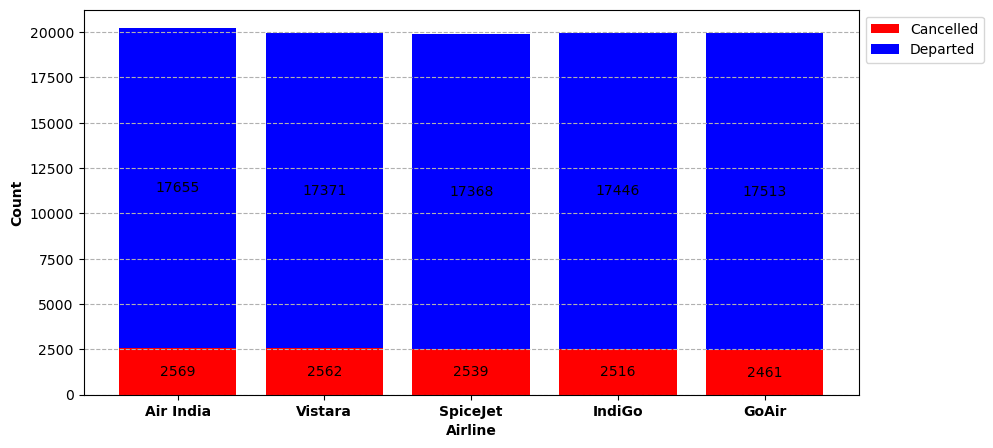

In [23]:
#stack bar plot
plt.figure(figsize=(10,5))

b1=plt.bar(airline_canc_dept["Airline"],airline_canc_dept["Canc"],color="r",bottom=0,label="Cancelled")
b2=plt.bar(airline_canc_dept["Airline"],airline_canc_dept["Dept"],color="b",bottom=airline_canc_dept["Canc"],label="Departed")
plt.bar_label(b1,label_type="center")
plt.bar_label(b2,label_type="center")
plt.xticks(fontweight="bold")
plt.xlabel("Airline",fontweight="bold")
plt.ylabel("Count",fontweight="bold")
plt.legend(bbox_to_anchor=(1,1))
plt.grid(axis="y",ls="--")
plt.show()

 

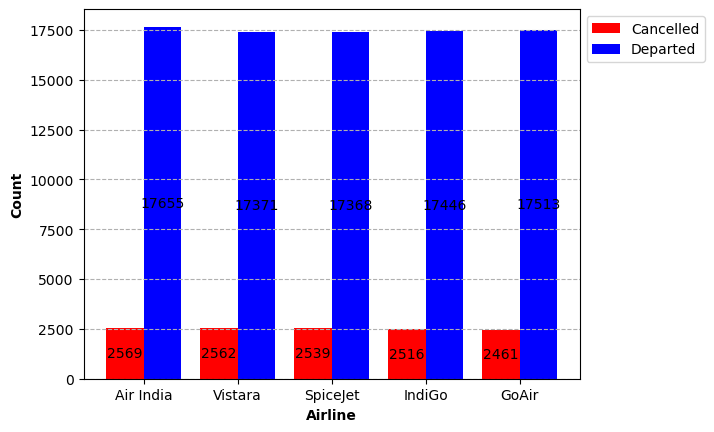

In [24]:
#clustered bar plot

a=np.arange(airline_canc_dept["Airline"].count())

b1=plt.bar(a-0.2,airline_canc_dept["Canc"],width=0.4,color="r",label="Cancelled")
b2=plt.bar(a+0.2,airline_canc_dept["Dept"],width=0.4,color="b",label="Departed")
plt.bar_label(b1,label_type="center")
plt.bar_label(b2,label_type="center")

plt.xticks(a,airline_canc_dept["Airline"])
plt.xlabel("Airline",fontweight="bold")
plt.ylabel("Count",fontweight="bold")
plt.legend(bbox_to_anchor=(1,1))
plt.grid(axis="y",ls="--")
plt.show()

In [25]:
airline_avg_pass

,Airline,canc_Passenger,dept_Passenger
0,Air India,100,148
1,GoAir,102,149
2,IndiGo,100,148
3,SpiceJet,100,147
4,Vistara,99,149


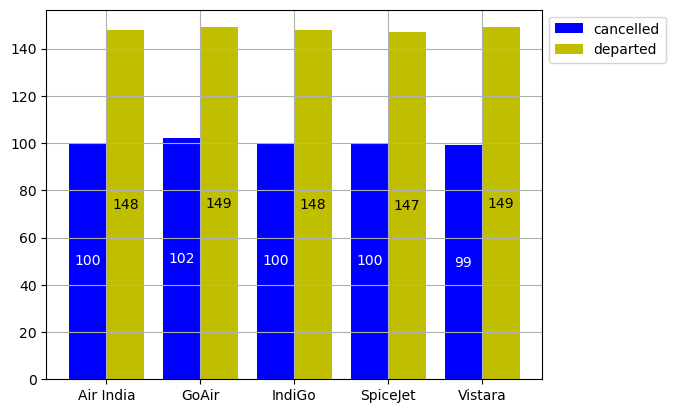

In [26]:
#cluster......
a=np.arange(len(airline_avg_pass["Airline"]))
b1=plt.bar(a-0.4/2,airline_avg_pass["canc_Passenger"],width=0.4,color="b",label="cancelled")
b2=plt.bar(a+0.4/2,airline_avg_pass["dept_Passenger"],width=0.4,color="y",label="departed")
plt.bar_label(b1,label_type="center",color="w")
plt.bar_label(b2,label_type="center")
plt.xticks(a,airline_avg_pass["Airline"])
plt.legend(bbox_to_anchor=(1,1))
plt.grid()
plt.show()

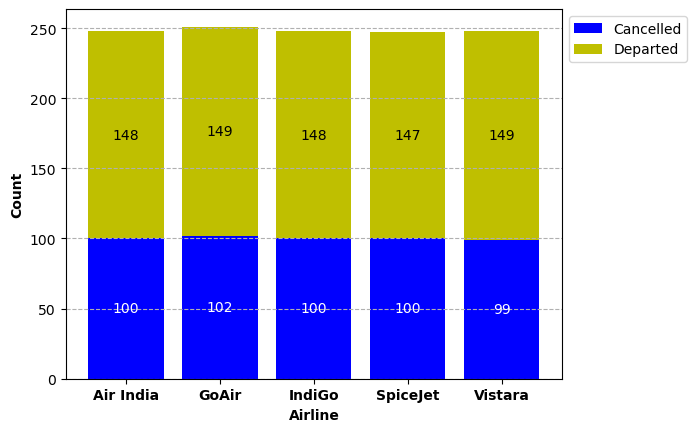

In [27]:
# stack........
b1=plt.bar(airline_avg_pass["Airline"],airline_avg_pass["canc_Passenger"],color="b",bottom=0,label="Cancelled")
b2=plt.bar(airline_avg_pass["Airline"],airline_avg_pass["dept_Passenger"],color="y",bottom=airline_avg_pass["canc_Passenger"],label="Departed")
plt.bar_label(b1,label_type="center",color="w")
plt.bar_label(b2,label_type="center")
plt.xticks(fontweight="bold")
plt.xlabel("Airline",fontweight="bold")
plt.ylabel("Count",fontweight="bold")
plt.legend(bbox_to_anchor=(1,1))
plt.grid(axis="y",ls="--")
plt.show()

In [28]:
airline_profit

,Profit
Air India,-1330308.62
GoAir,-19141215.82
IndiGo,-7176895.38
SpiceJet,-12939771.02
Vistara,10503694.83


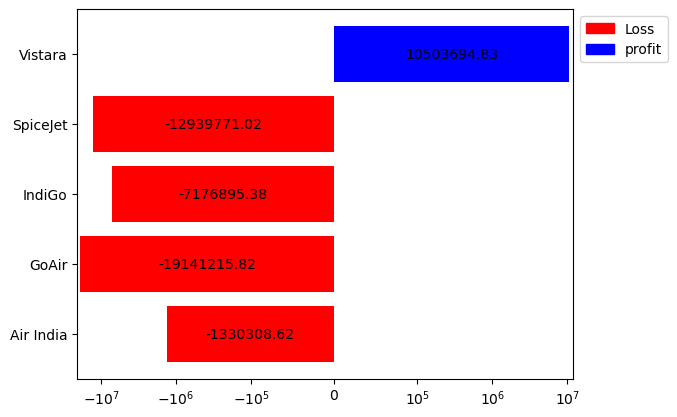

In [29]:

from matplotlib.patches import Patch

b1=plt.barh(airline_profit.index,airline_profit["Profit"],color=["red" if i<0 else "blue" for i in airline_profit["Profit"]])
plt.bar_label(b1,fmt="%.2f",label_type="center")
plt.xscale(value="symlog",linthresh=1e5)
plt.legend(handles=[Patch(color="red",label="Loss"),Patch(color="blue",label="profit")],bbox_to_anchor=(1,1))
plt.show()

In [30]:
airline_ontime_delayed

,ontime,delayed
Airline,,
Air India,3799,16425
GoAir,3776,16198
IndiGo,3749,16213
SpiceJet,3765,16142
Vistara,3733,16200


In [31]:
ontime=df[df["Delay_minutes"]<="00:01:00"].groupby("Airline").agg(ontime=("Flight_Number","count"))
delayed=df[df["Delay_minutes"]>"00:01:00"].groupby("Airline").agg(delayed=("Flight_Number","count"))
airline_ontime_delayed=pd.merge(ontime,delayed,how="inner",on="Airline")

In [32]:
airline_ontime_delayed.index

Index(['Air India', 'GoAir', 'IndiGo', 'SpiceJet', 'Vistara'], dtype='object', name='Airline')

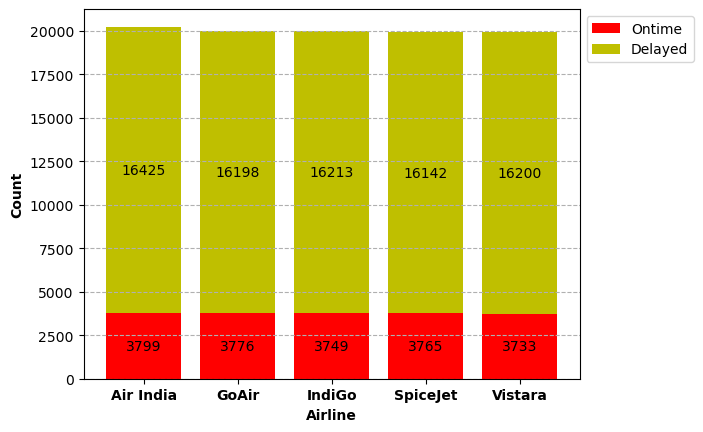

In [33]:
#stake bar graph 

b1=plt.bar(airline_ontime_delayed.index,airline_ontime_delayed["ontime"],color="r",bottom=0,label="Ontime")
b2=plt.bar(airline_ontime_delayed.index,airline_ontime_delayed["delayed"],color="y",bottom=airline_ontime_delayed["ontime"],label="Delayed")
plt.bar_label(b1,label_type="center")
plt.bar_label(b2,label_type="center")
plt.xticks(fontweight="bold")
plt.xlabel("Airline",fontweight="bold")
plt.ylabel("Count",fontweight="bold")
plt.legend(bbox_to_anchor=(1,1))
plt.grid(axis="y",ls="--")
plt.show()

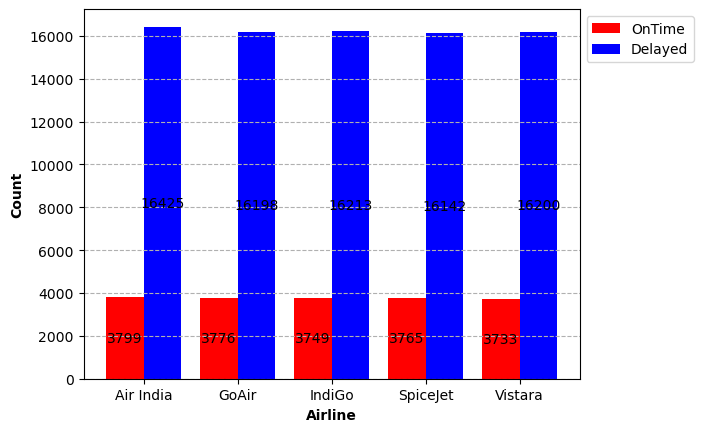

In [34]:
#clustered bar graph
import matplotlib.pyplot as plt
import numpy as np

airline_ontime_delayed = airline_ontime_delayed.reset_index()
a = np.arange(len(airline_ontime_delayed))
b1 = plt.bar(a - 0.2, airline_ontime_delayed["ontime"], width=0.4, color="r", label="OnTime")
b2 = plt.bar(a + 0.2, airline_ontime_delayed["delayed"], width=0.4, color="b", label="Delayed")
plt.bar_label(b1, label_type="center")
plt.bar_label(b2, label_type="center")
plt.xticks(a, airline_ontime_delayed["Airline"])
plt.xlabel("Airline", fontweight="bold")
plt.ylabel("Count", fontweight="bold")
plt.legend(bbox_to_anchor=(1,1))
plt.grid(axis="y", ls="--")

plt.show()


In [35]:
airline_org_count_canc=airline_org_count_dept

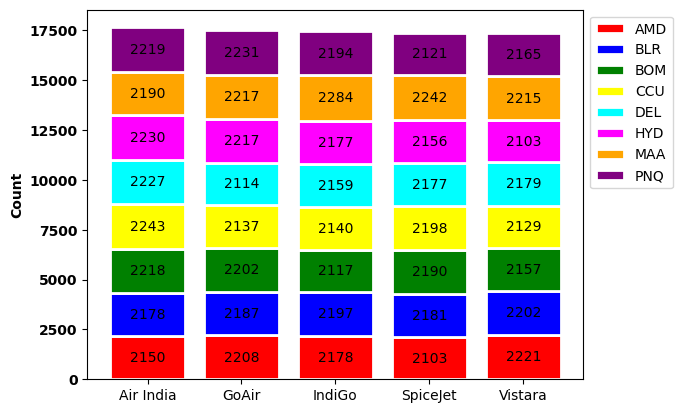

In [36]:
colour=["red","blue","green","yellow","cyan","magenta","orange","purple"]
x=range(len(airline_org_count_canc.index))
for i in x:
    bottom =0
    for ind,org in enumerate(airline_org_count_canc.columns):
        value=airline_org_count_canc.iloc[i,ind]
        b1=plt.bar(i,value,bottom=bottom,color=colour[ind],edgecolor="white",linewidth=2,label=org if i==0 else None)
        plt.bar_label(b1,label_type="center",color="k")
        bottom+=value
plt.yticks(fontweight="bold")
plt.ylabel("Count",fontweight="bold")
plt.xticks(x,airline_org_count_canc.index)
plt.legend(bbox_to_anchor=(1,1))
plt.show()
        

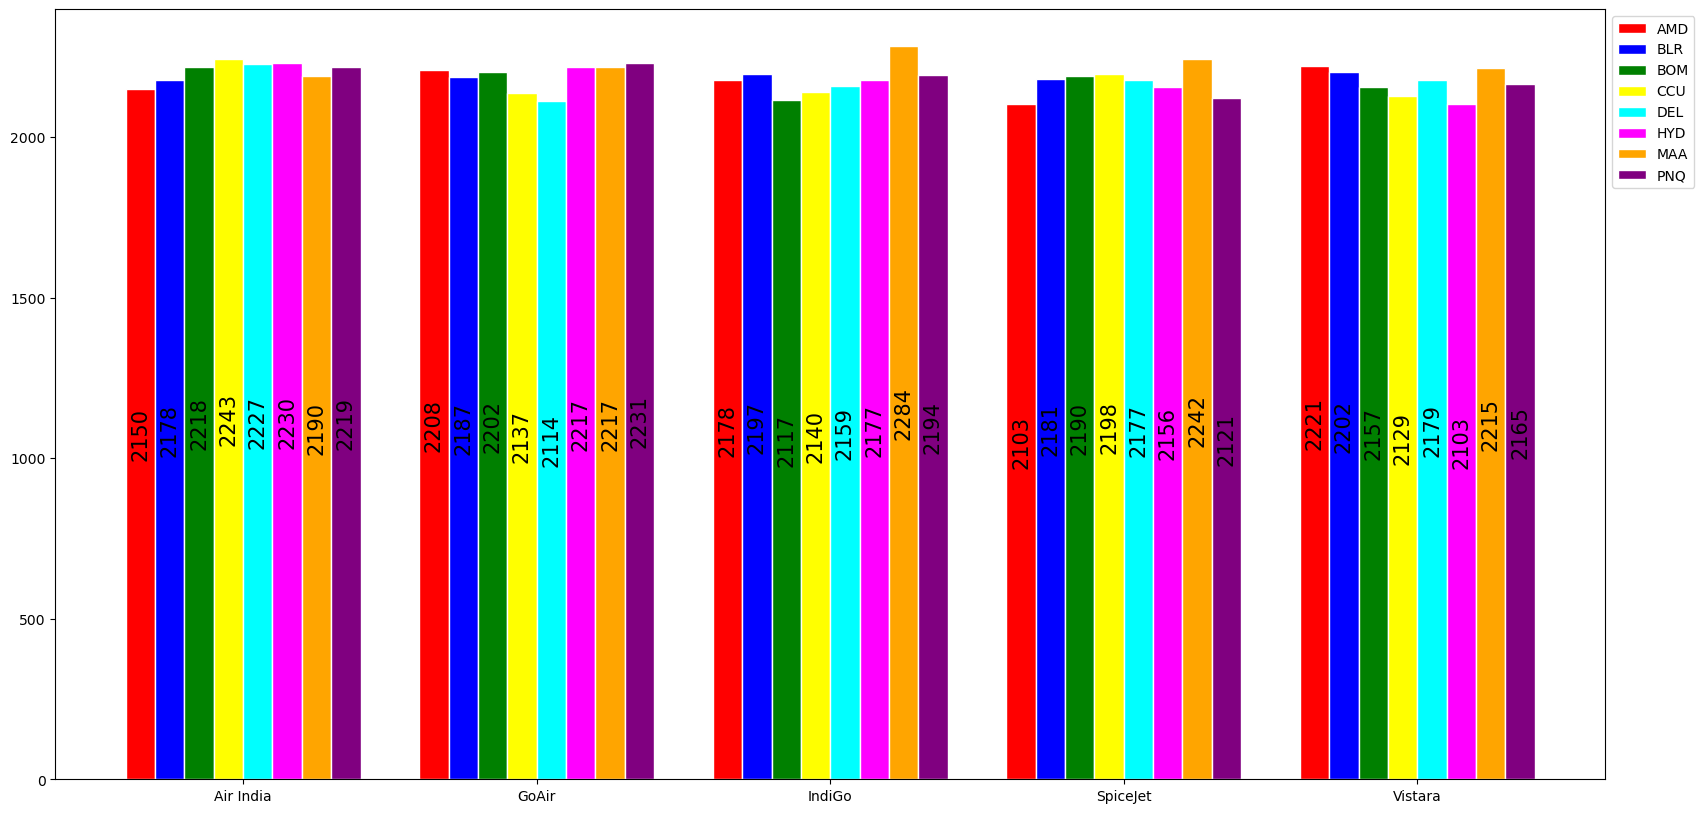

In [37]:
#airline origin count
colour=["red","blue","green","yellow","cyan","magenta","orange","purple"]
plt.figure(figsize=(20,10))
bar_width=0.8/len(airline_org_count_dept.columns)
for i in x:
    xpo=i-0.4+bar_width/2
    for ind,org in enumerate(airline_org_count_canc.columns):
        xpo=i-0.4+bar_width/2+ind*bar_width
        value=airline_org_count_canc.iloc[i,ind]
        b1=plt.bar(xpo,value,width=bar_width,color=colour[ind],edgecolor="white",linewidth=1,label=org if i==0 else None)
        plt.bar_label(b1,label_type="center",rotation=90,fontsize=15,color="k")
plt.xticks(x,airline_org_count_canc.index)
plt.legend(bbox_to_anchor=(1,1))
plt.show()


In [38]:

pd.DataFrame(df[df["Distance_km"]!=0].groupby("Airline")["Origin"].value_counts()).reset_index().pivot(index="Airline",columns="Origin",values="count").astype("int")

Origin,AMD,BLR,BOM,CCU,DEL,HYD,MAA,PNQ
Airline,,,,,,,,
Air India,2150,2178,2218,2243,2227,2230,2190,2219
GoAir,2208,2187,2202,2137,2114,2217,2217,2231
IndiGo,2178,2197,2117,2140,2159,2177,2284,2194
SpiceJet,2103,2181,2190,2198,2177,2156,2242,2121
Vistara,2221,2202,2157,2129,2179,2103,2215,2165


In [39]:
airline_org_count_canc.index=airline_org_count_dept.index
air=airline_org_count_dept.index

C:\Users\asus\AppData\Local\Temp\ipykernel_21768\1173148455.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1,1))


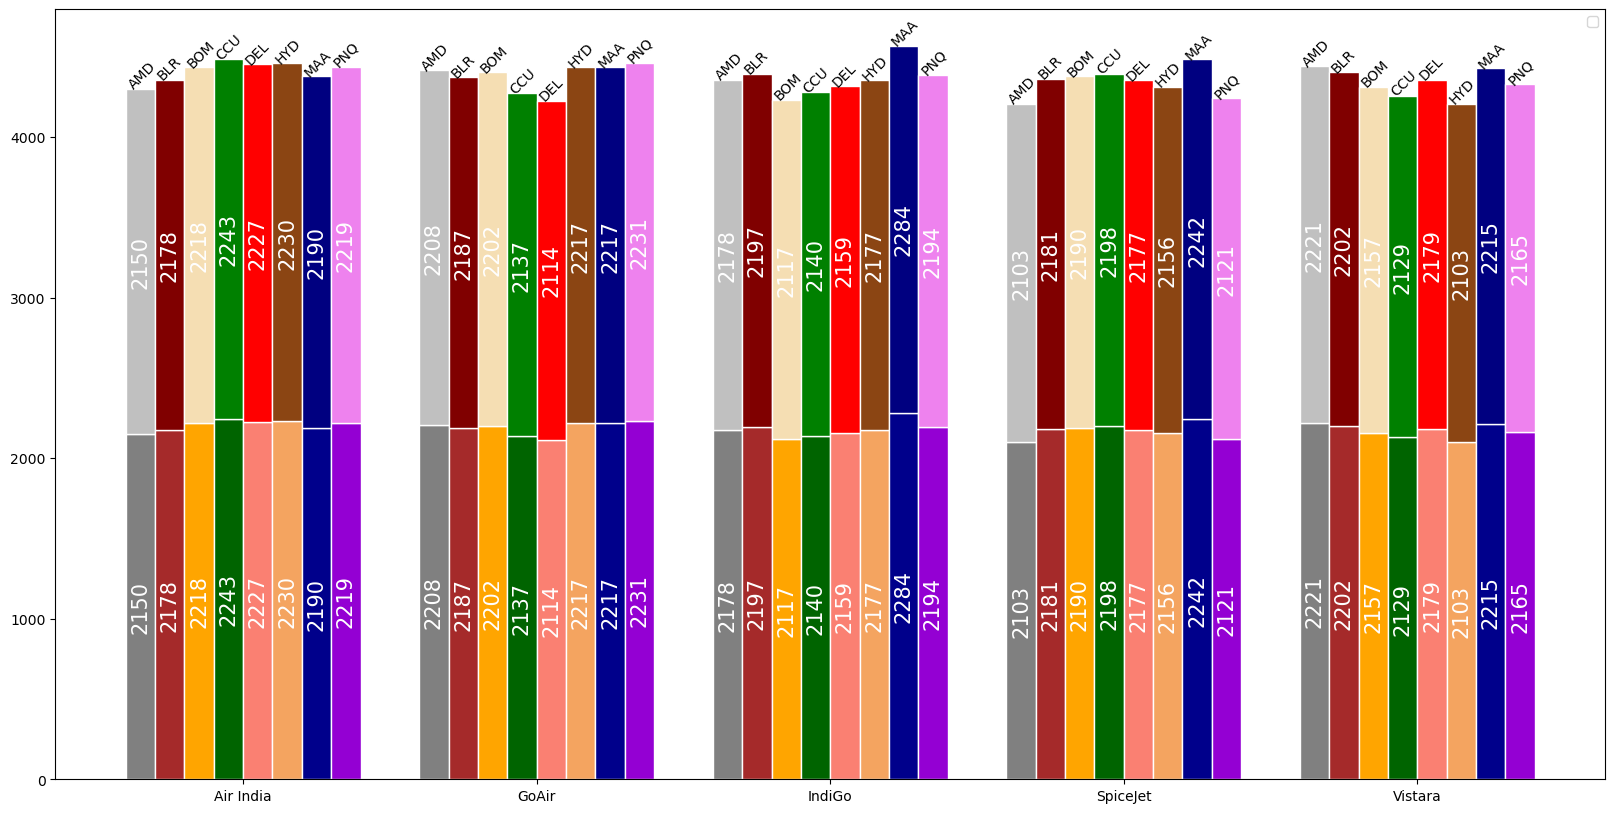

In [40]:
air=airline_org_count_canc.index
x=np.arange(len(air))
orgin=airline_org_count_canc.columns
bar_width=0.8/len(orgin)
plt.figure(figsize=(20,10))
colours=[["grey","silver"],["brown","maroon"],["orange","wheat"],["darkgreen","green"],["salmon","red"],["sandybrown","saddlebrown"],["darkblue","navy"],["darkviolet","violet"]]
for i in x:
    for ind,org in enumerate(orgin):
        canc,dept,bottom=airline_org_count_canc.iat[i,ind],airline_org_count_dept.iat[i,ind],0
        xpo=i-0.4+bar_width/2+ind*bar_width
        b1=plt.bar(xpo,canc,bottom=bottom,width=bar_width,color=colours[ind][0],edgecolor="white")
        bottom+=canc
        b2=plt.bar(xpo,dept,bottom=bottom,width=bar_width,color=colours[ind][1],edgecolor="white")
        plt.bar_label(b1,color="white",label_type="center",fontsize=15,rotation=90)
        plt.bar_label(b2,color="white",label_type="center",fontsize=15,rotation=90)
        bottom+=dept+1
        plt.text(xpo-bar_width/2,bottom,org,fontsize=10,rotation=45)
plt.xticks(x,air)
plt.legend(bbox_to_anchor=(1,1))
plt.show()
        


In [41]:
airline_toff_count

,1,2,3,4,5
SpiceJet,1906,270,27,3,0
IndiGo,1909,257,27,3,0
GoAir,1863,250,27,3,1
Air India,1912,276,31,3,0
Vistara,1926,267,26,6,0


<Axes: >

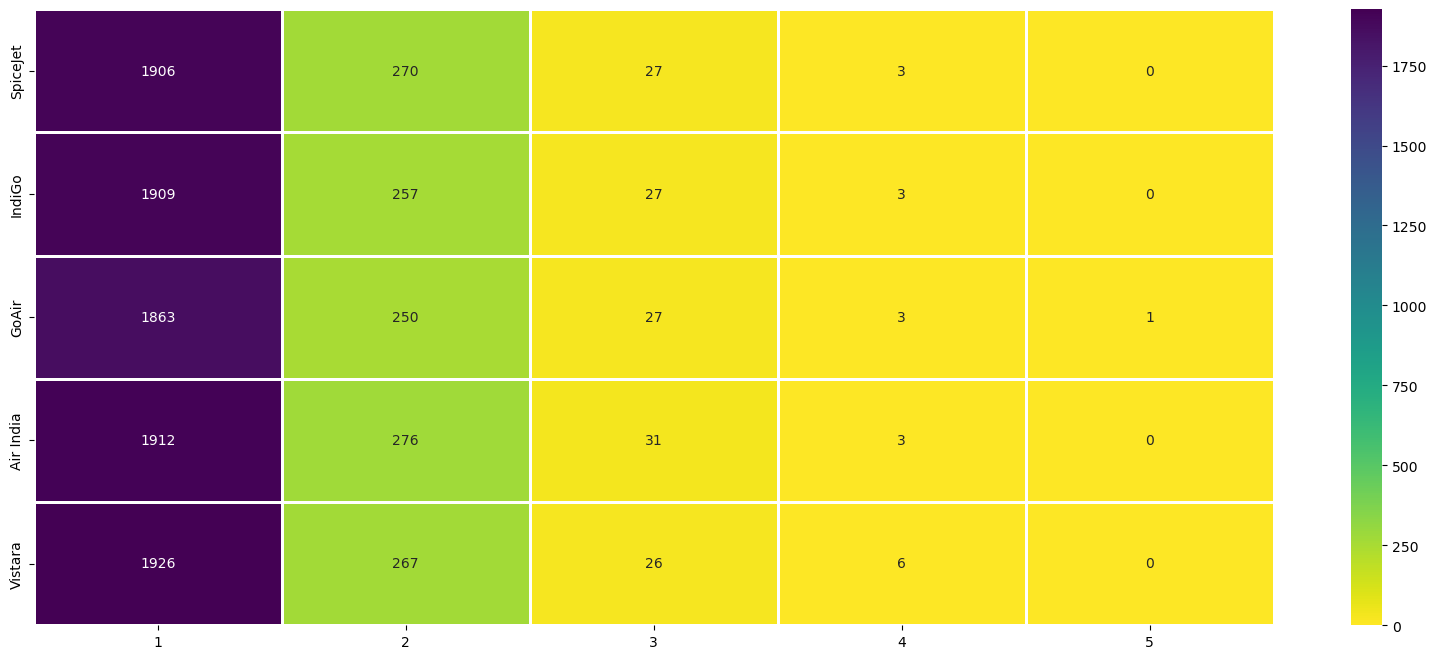

In [42]:
#airline take off count 
plt.figure(figsize=(20,8))
sns.heatmap(airline_toff_count,annot=True,fmt="d",linecolor="white",linewidths=1,cmap="viridis_r")

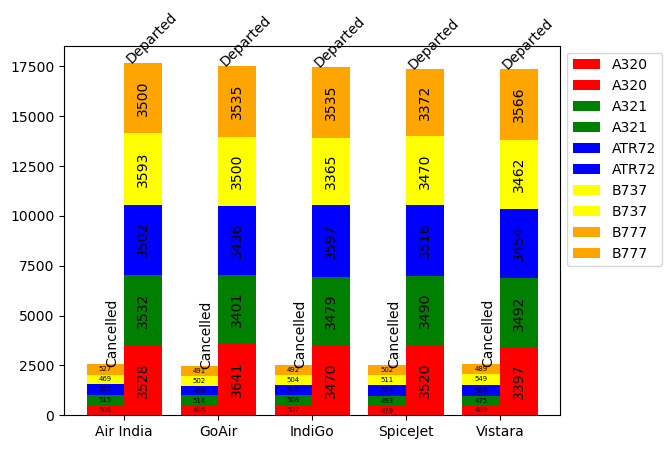

In [43]:
#airline aircraft cancel departed 
air=AACD["Airline"].unique()
x=np.arange(len(air))
atype=AACD["Aircraft_Type"].unique()
bar_width=0.4
colour=["red","green","blue","yellow","orange"]
for i,airline in enumerate(air):
    temp=AACD[AACD["Airline"]==airline].drop("Airline",axis=1).set_index("Aircraft_Type")
    canb,depb=0,0
    for j,aircraft in enumerate(atype):
        can,dept=temp.at[aircraft,"canc_count"],temp.at[aircraft,"dept_count"]
        b1=plt.bar(i-bar_width/2,can,width=bar_width,bottom=canb,color=colour[j],label=aircraft if i==0 else None)
        canb+=can
        b2=plt.bar(i+bar_width/2,dept,width=bar_width,bottom=depb,color=colour[j],label=aircraft if i==0 else None)
        depb+=dept
        plt.bar_label(b1,color="black",label_type="center",fontsize=5)
        plt.bar_label(b2,color="black",label_type="center",fontsize=10,rotation=90)
    plt.text(i-bar_width/2,canb+10,"Cancelled",rotation=90,fontsize=10)
    plt.text(i,depb+10,"Departed",rotation=45,fontsize=10)
plt.xticks(x,air)
plt.legend(bbox_to_anchor=(1,1))
plt.show()





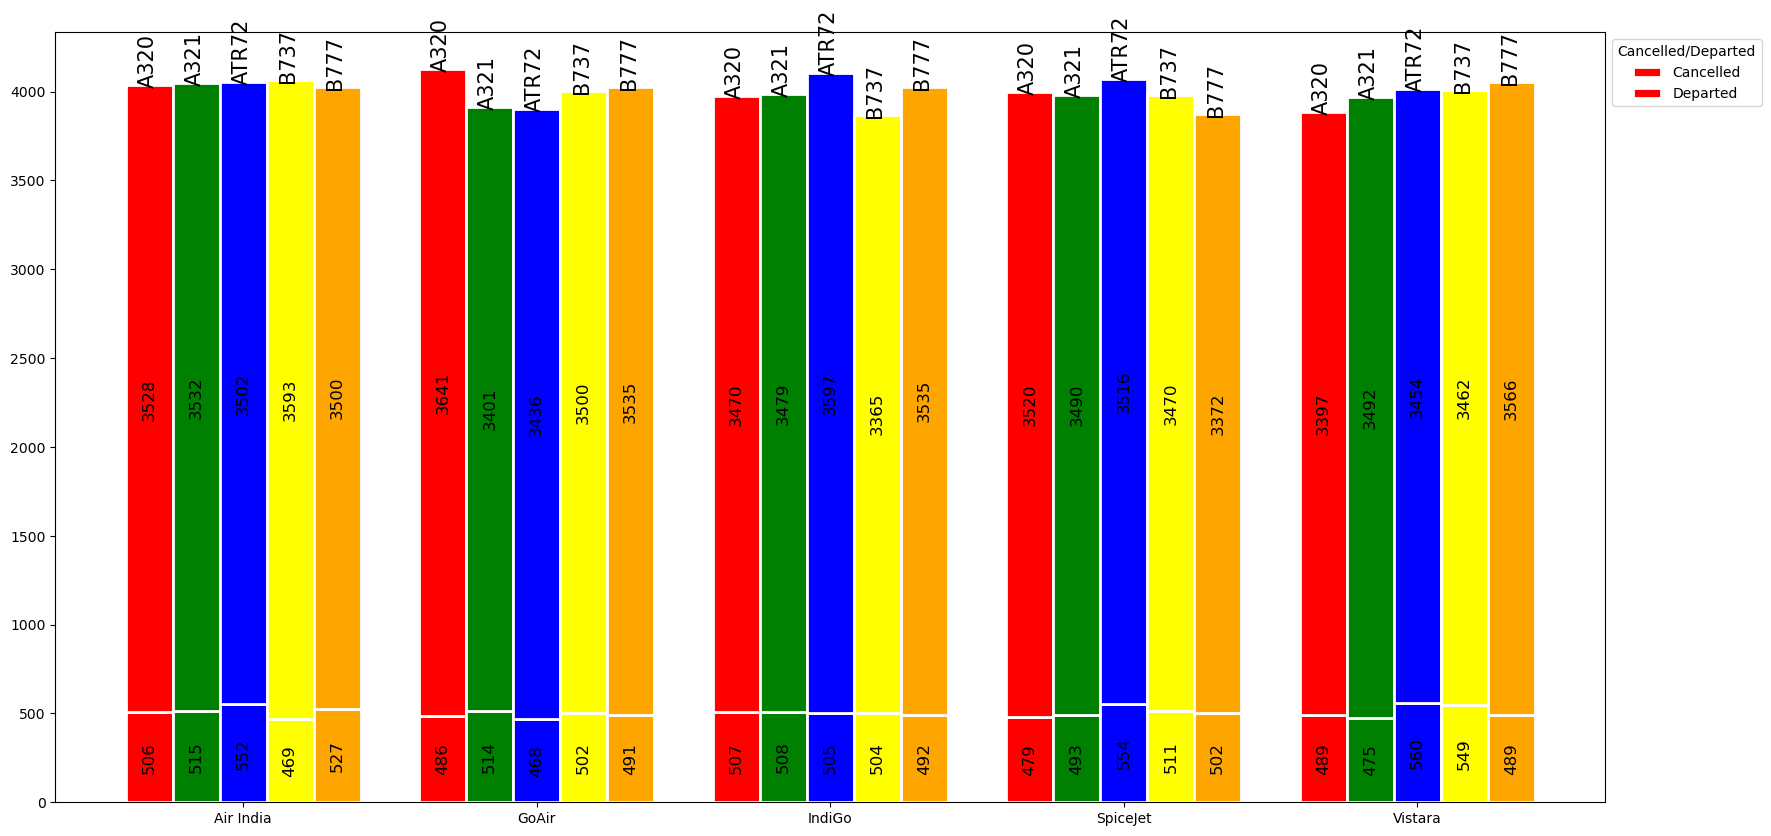

In [44]:
#airline aircraft cancel departed 
plt.figure(figsize=(20,10))
air=AACD["Airline"].unique()
x=np.arange(len(air))
atype=AACD["Aircraft_Type"].unique()
bar_width=0.8/len(atype)
colour=["red","green","blue","yellow","orange"]
for i,airline in enumerate(air):
    temp=AACD[AACD["Airline"]==airline].drop("Airline",axis=1).set_index("Aircraft_Type")
    for j,aircraft in enumerate(atype):
        bottom,can,dept=0,temp.at[aircraft,"canc_count"],temp.at[aircraft,"dept_count"]
        xpo=i-0.4+bar_width/2+j*bar_width
        b1=plt.bar(xpo,can,width=bar_width,bottom=bottom,color=colour[j],edgecolor="white",linewidth=2,label="Cancelled" if i==0 and j==0 else None)
        b2=plt.bar(xpo,dept,width=bar_width,bottom=can,color=colour[j],edgecolor="white",linewidth=2,label="Departed" if i==0 and j==0 else None)
        plt.bar_label(b1,color="black",label_type="center",fontsize=12,rotation=90)
        plt.bar_label(b2,color="black",label_type="center",fontsize=12,rotation=90)
        plt.text(xpo-bar_width/4,can+dept+8,aircraft,rotation=90,fontsize=15)
plt.xticks(x,air)
plt.legend(title="Cancelled/Departed",bbox_to_anchor=(1,1))
plt.show()

In [45]:
AACDPA#[AACDPA["Airline"]=="Air India"].drop("Airline",axis=1).set_index("Aircraft_Type")

,Airline,Aircraft_Type,avg_canc,avg_dept
0,Air India,A320,91.02,133.82
1,Air India,A321,111.54,164.32
2,Air India,ATR72,35.03,51.87
3,Air India,B737,88.75,130.52
4,Air India,B777,177.29,261.21
5,GoAir,A320,91.26,134.17
6,GoAir,A321,111.62,164.34
7,GoAir,ATR72,35.07,51.97
8,GoAir,B737,88.46,130.18
9,GoAir,B777,178.63,261.96


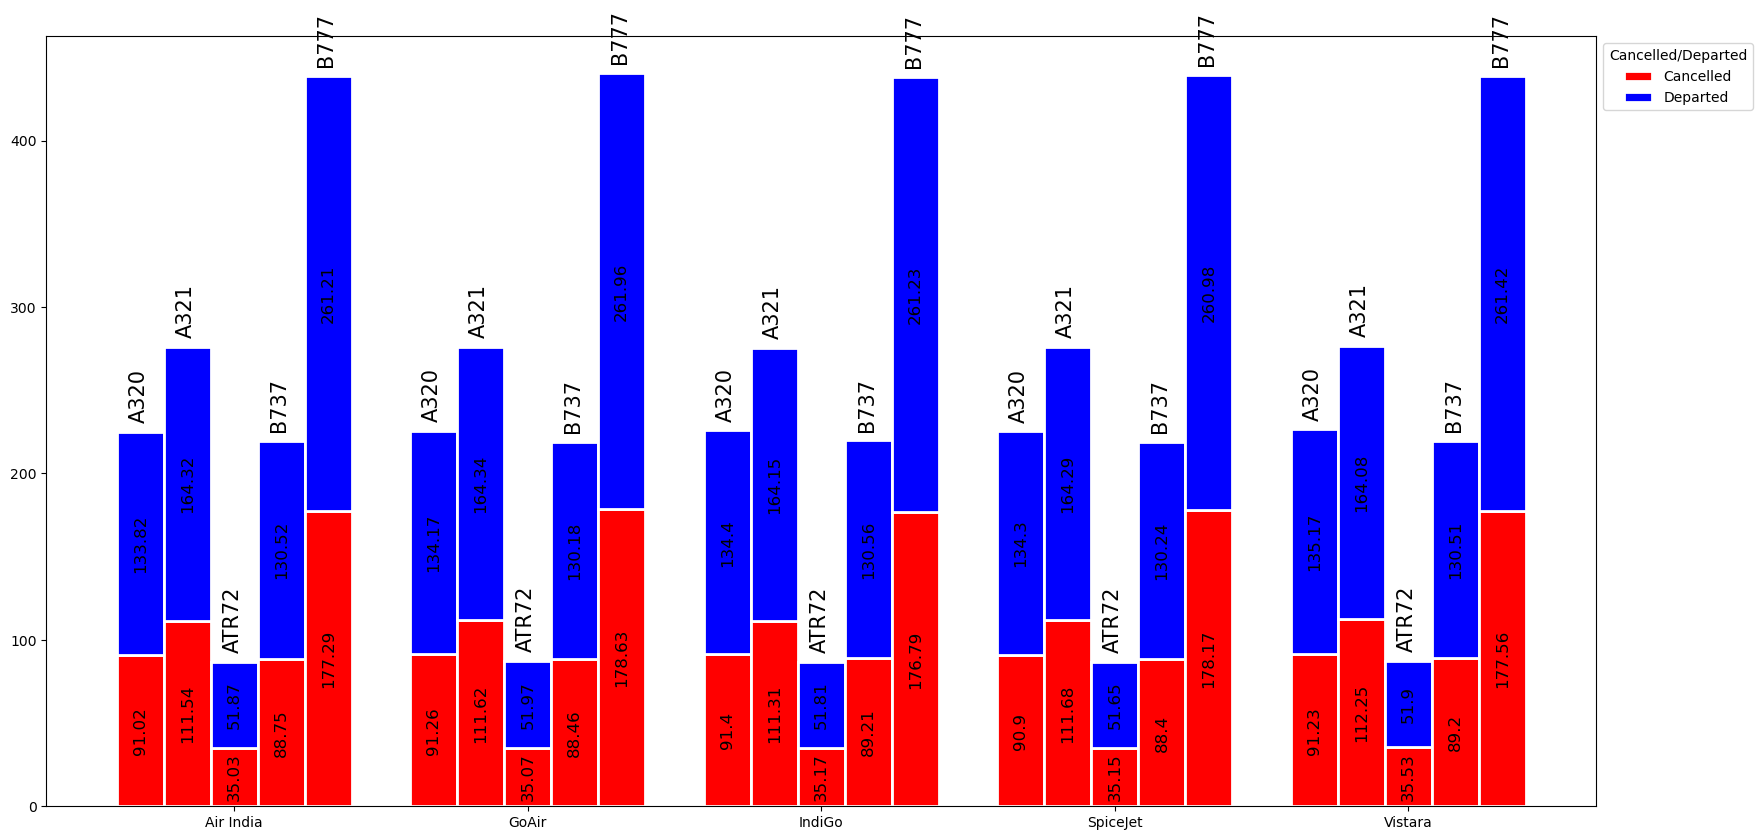

In [46]:
#airline aircraft can departed passenger average 
plt.figure(figsize=(20,10))
air=AACDPA["Airline"].unique()
x=np.arange(len(air))
atype=AACDPA["Aircraft_Type"].unique()
bar_width=0.8/len(atype)
for i,airline in enumerate(air):
    temp=AACDPA[AACDPA["Airline"]==airline].drop("Airline",axis=1).set_index("Aircraft_Type")
    for j,aircraft in enumerate(atype):
        bottom,can,dept=0,temp.at[aircraft,"avg_canc"],temp.at[aircraft,"avg_dept"]
        xpo=i-0.4+bar_width/2+j*bar_width
        b1=plt.bar(xpo,can,width=bar_width,bottom=bottom,color="red",edgecolor="white",linewidth=2,label="Cancelled" if i==0 and j==0 else None)
        b2=plt.bar(xpo,dept,width=bar_width,bottom=can,color="blue",edgecolor="white",linewidth=2,label="Departed" if i==0 and j==0 else None)
        plt.bar_label(b1,color="black",label_type="center",fontsize=12,rotation=90)
        plt.bar_label(b2,color="black",label_type="center",fontsize=12,rotation=90)
        plt.text(xpo-bar_width/4,can+dept+8,aircraft,rotation=90,fontsize=15)
plt.xticks(x,air)
plt.legend(title="Cancelled/Departed",bbox_to_anchor=(1,1))
plt.show()

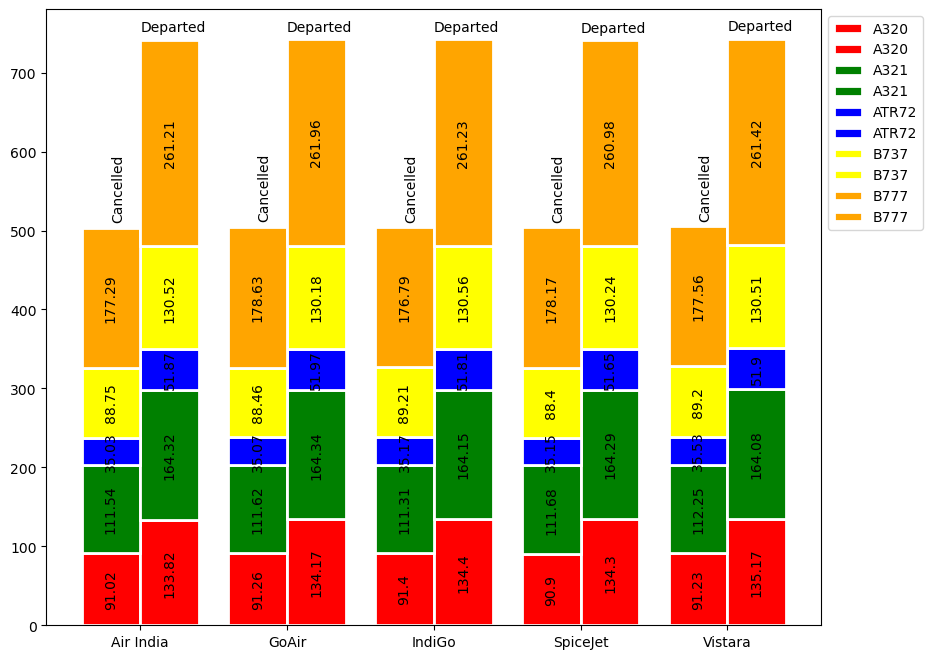

In [47]:
#airline aircraft can departed passenger average
plt.figure(figsize=(10,8))
air=AACDPA["Airline"].unique()
x=np.arange(len(air))
atype=AACDPA["Aircraft_Type"].unique()
bar_width=0.4
colour=["red","green","blue","yellow","orange"]
for i,airline in enumerate(air):
    temp=AACDPA[AACDPA["Airline"]==airline].drop("Airline",axis=1).set_index("Aircraft_Type")
    canb,depb=0,0
    for j,aircraft in enumerate(atype):
        can,dept=temp.at[aircraft,"avg_canc"],temp.at[aircraft,"avg_dept"]
        b1=plt.bar(i-bar_width/2,can,width=bar_width,bottom=canb,color=colour[j],edgecolor="white",linewidth=2,label=aircraft if i==0 else None)
        canb+=can
        b2=plt.bar(i+bar_width/2,dept,width=bar_width,bottom=depb,color=colour[j],edgecolor="white",linewidth=2,label=aircraft if i==0 else None)
        depb+=dept
        plt.bar_label(b1,color="black",label_type="center",fontsize=10,rotation=90)
        plt.bar_label(b2,color="black",label_type="center",fontsize=10,rotation=90)
    plt.text(i-bar_width/2,canb+10,"Cancelled",rotation=90,fontsize=10)
    plt.text(i,depb+10,"Departed",fontsize=10)
plt.xticks(x,air)
plt.legend(bbox_to_anchor=(1,1))
plt.show()


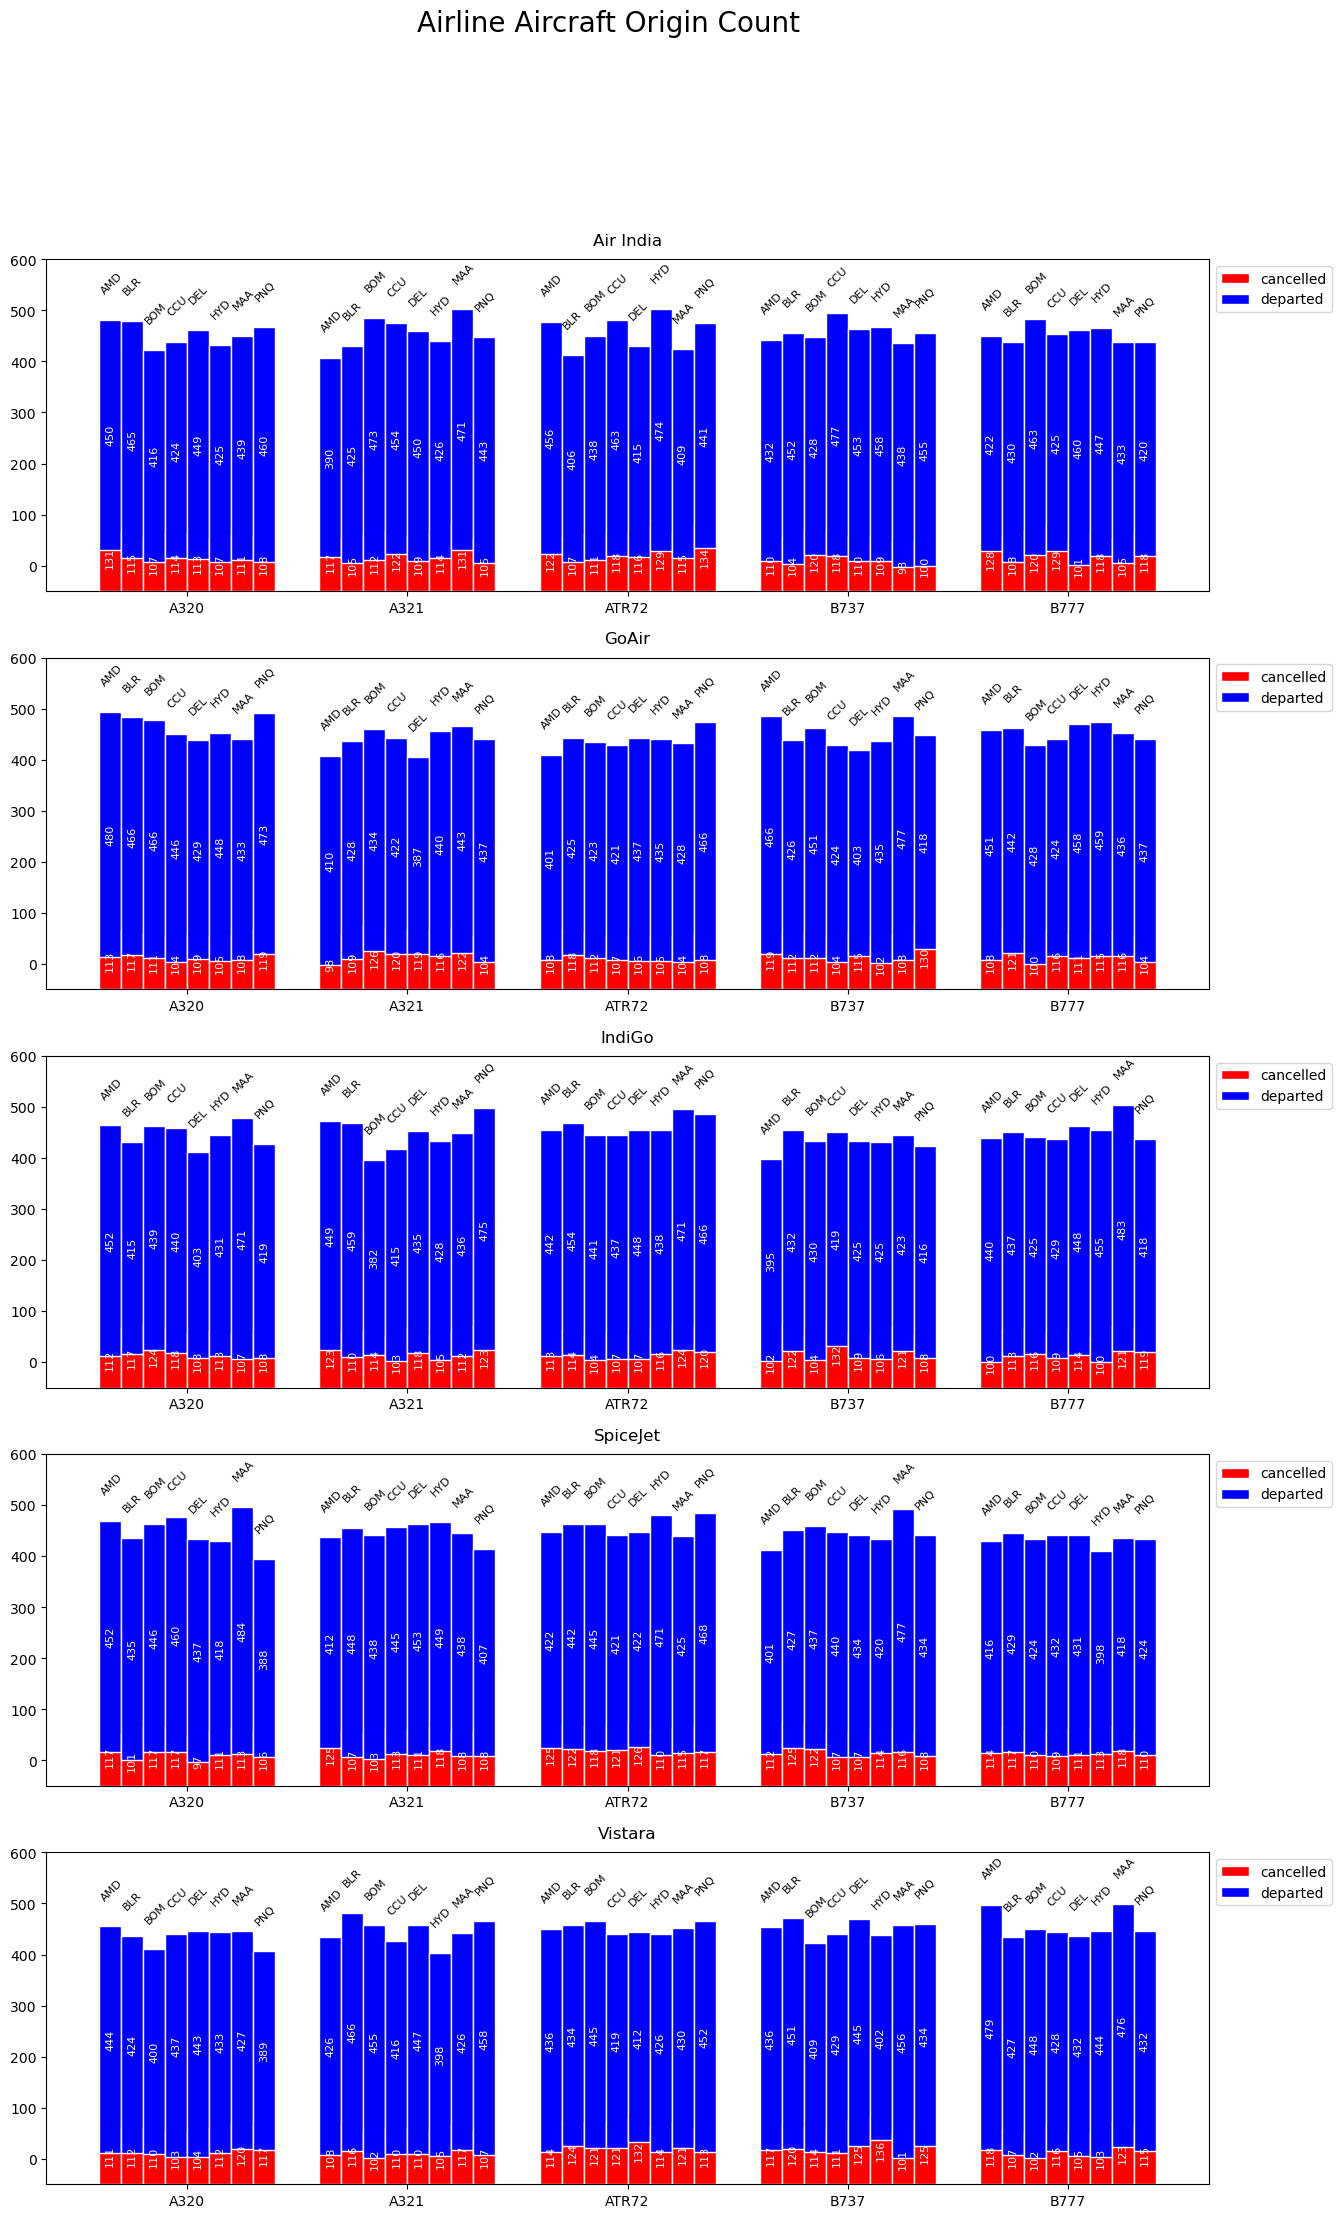

In [48]:
air=AAOC["Airline"].unique()
fig,axes=plt.subplots(len(air),1,figsize=(15,5*len(air)))
for aind,airline in enumerate(air):
    ax=axes[aind]
    temp1=AAOC[AAOC["Airline"]==airline].drop("Airline",axis=1)
    atype=temp1["Aircraft_Type"].unique()
    x=np.arange(len(atype))
    for atind,aircraft in enumerate(atype):
        temp2=temp1[temp1["Aircraft_Type"]==aircraft].drop("Aircraft_Type",axis=1).set_index("Origin")
        Origin=temp2.index
        bar_width=0.8/len(Origin)
        bottoms=-50
        for oind,org in enumerate(Origin):
            xpo=atind-0.4+bar_width/2+oind*bar_width
            can,dep=temp2.at[org,"canc_count"],temp2.at[org,"dept_count"]
            b1=ax.bar(xpo,can-bottoms,bottom=bottoms,width=bar_width,color="red",edgecolor="white",linewidth=1,label="cancelled" if (atind==0 and oind==0) else None)
            b2=ax.bar(xpo,dep,bottom=can+bottoms,width=bar_width,color="blue",edgecolor="white",linewidth=1,label="departed" if (atind==0 and oind==0) else None)
            ax.bar_label(b1,label_type="center",color="white",fontsize=8,rotation=90)
            ax.bar_label(b2,label_type="center",color="white",fontsize=8,rotation=90)
            ax.text(xpo-bar_width/2,can+dep+1,org,fontsize=8,rotation=45)
        ax.set_xticks(x,atype)
        ax.set_ylim(bottom=-50,top=600)
        ax.legend(bbox_to_anchor=(1,1))
    ax.set_title(airline,pad=10)
    #plt.subtitles(Airline)
plt.suptitle("Airline Aircraft Origin Count",fontsize=20)
plt.show()



In [49]:
#...............14th may.................

In [50]:
AATFT

Aircraft_Type,A320,A321,ATR72,B737,B777
Airline,,,,,
Air India,255 days 11:31:16,253 days 22:33:23,381 days 21:41:26,262 days 17:46:26,242 days 11:52:49
GoAir,264 days 09:01:06,243 days 03:03:04,371 days 08:26:48,255 days 11:03:26,246 days 04:25:32
IndiGo,252 days 22:46:27,250 days 01:44:12,387 days 14:44:30,246 days 09:06:24,244 days 07:13:58
SpiceJet,255 days 03:41:53,251 days 10:15:13,376 days 06:44:47,252 days 09:56:48,234 days 06:09:45
Vistara,247 days 11:43:49,250 days 18:13:43,369 days 23:50:01,253 days 08:49:24,246 days 16:33:12


In [51]:
temp1 = AATFT.unstack(level=0).reset_index()
temp1[0]=temp1[0].apply(lambda x: x.total_seconds())
tep1=temp1.pivot(index="Airline",columns="Aircraft_Type",values=0).astype("int")

In [52]:
tep1

Aircraft_Type,A320,A321,ATR72,B737,B777
Airline,,,,,
Air India,22073476,21940403,32996486,22700786,20951569
GoAir,22842066,21006184,32084808,22071806,21270332
IndiGo,21854787,21606252,33489870,21287184,21107638
SpiceJet,22045313,21723313,32510687,21808608,20239785
Vistara,21383029,21665623,31967401,21890964,21313992


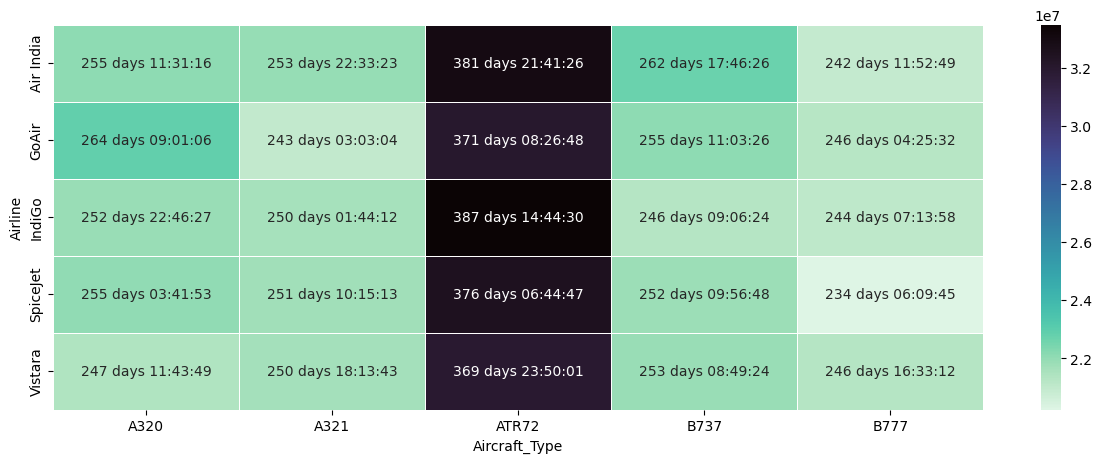

In [53]:
# heatmap shows = the darker the color lower the value and vice versa
plt.figure(figsize=(15,5))
sns.heatmap(tep1,annot=AATFT.astype("str"),fmt="",annot_kws={"size": 10},linecolor="white",linewidths=0.5,cmap="mako_r")
plt.show()

In [54]:
#airline aircraft profit
AAP

Aircraft_Type,A320,A321,ATR72,B737,B777
Airline,,,,,
Air India,-806253.252,404201.254,1682202.744,-1244890.218,-1365569.128
GoAir,-4353068.869,-3305750.868,-1518613.812,-4549833.925,-5413948.335
IndiGo,-1996354.210,-957465.884,710820.703,-2273932.862,-2659963.129
SpiceJet,-3113600.400,-2278917.823,-327946.344,-3336576.286,-3882730.173
Vistara,1267496.987,2961344.169,4053894.072,972285.591,1248674.002


<Axes: xlabel='Aircraft_Type', ylabel='Airline'>

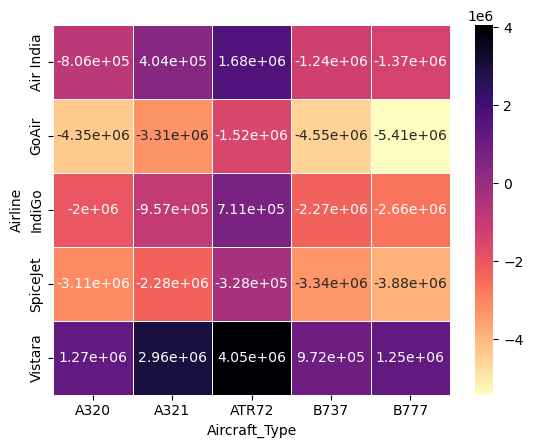

In [55]:
#airline aircraft profit
sns.heatmap(AAP,annot=True,fmt=".3",linecolor="white",linewidths=0.5,cmap="magma_r")

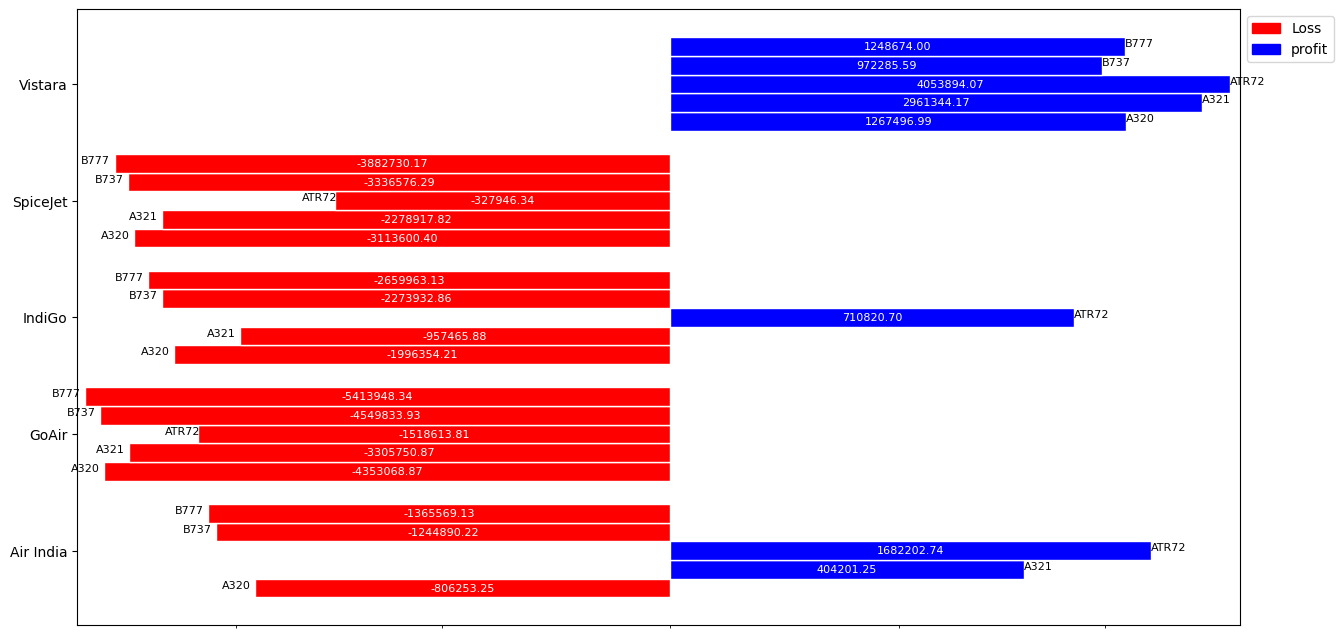

In [56]:
from matplotlib.patches import Patch
air=AAP.index
y=np.arange(len(air))
atype=AAP.columns
bar_width=0.8/len(atype)
plt.figure(figsize=(15,8))
for aind,airline in enumerate(air):
    for atind,aircraft in enumerate(atype):
        ypo=aind-0.4+bar_width/2+atind*bar_width
        value=AAP.at[airline,aircraft]
        b1=plt.barh(ypo,value,height=bar_width,color="red" if value<0 else "blue",edgecolor="white")
        plt.bar_label(b1,fmt="%.2f",label_type="center",color="white",fontsize=8)
        plt.text(value if value>0 else value+(value*0.45),ypo,aircraft,fontsize=8)
plt.xscale("symlog",linthresh=1e5)
plt.xticks([])
plt.yticks(y,air)
plt.legend(handles=[Patch(color="red",label="Loss"),Patch(color="blue",label="profit")],bbox_to_anchor=(1,1))
plt.show()

In [57]:
AAWCD

,Airline,Aircraft_Type,Weather_Condition,canc,dept
0,Air India,A320,Clear,1789,267
1,Air India,A320,Cloudy,1043,138
2,Air India,A320,Foggy,160,27
3,Air India,A320,Rainy,536,74
4,Air India,A321,Clear,1797,258
...,...,...,...,...,...
95,Vistara,B737,Rainy,525,69
96,Vistara,B777,Clear,1774,235
97,Vistara,B777,Cloudy,1071,152
98,Vistara,B777,Foggy,173,22


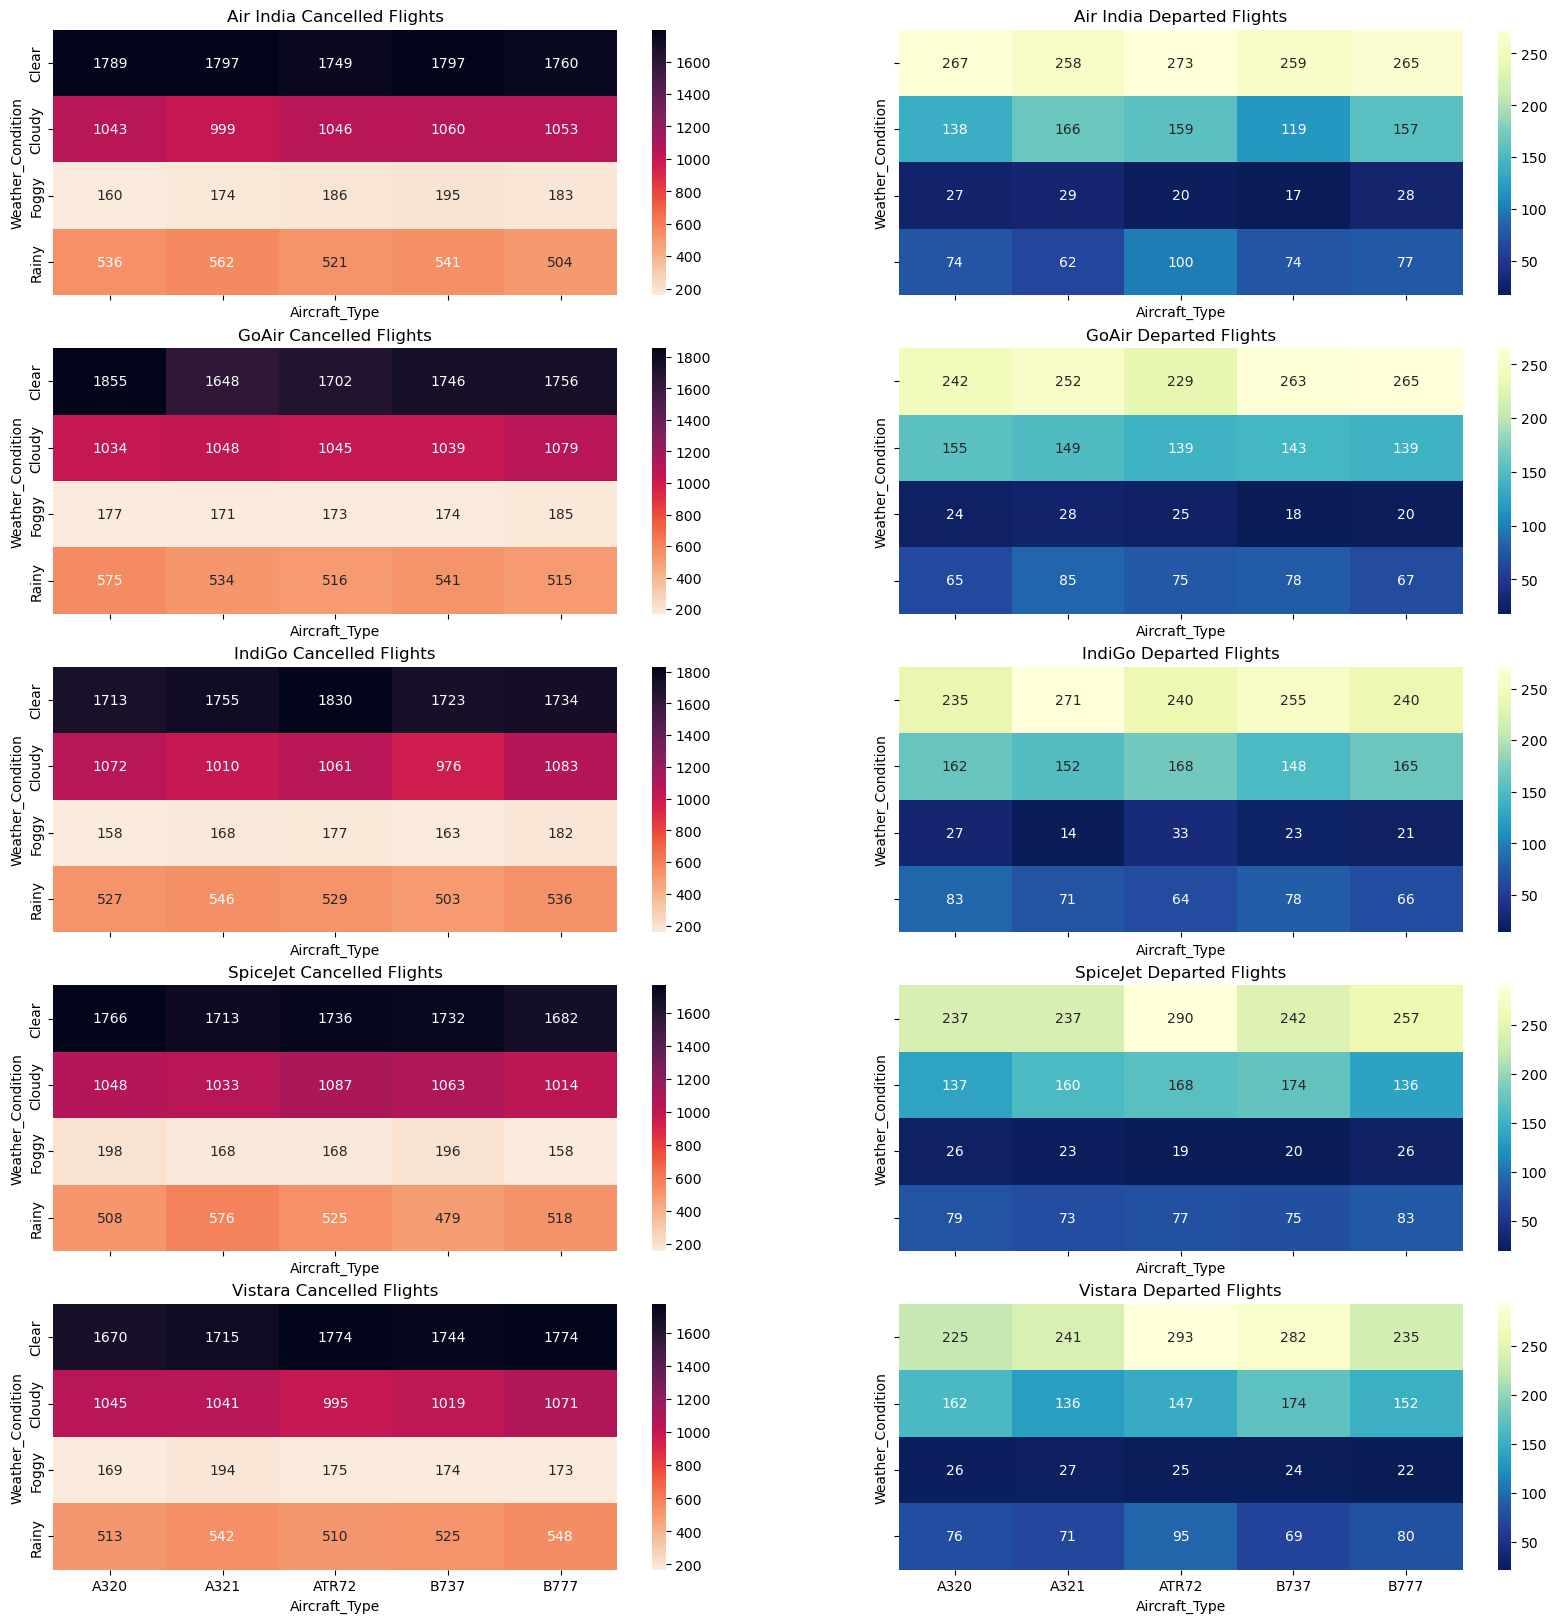

In [58]:
################18th may##############
air=AAWCD["Airline"].unique()
fig,axes=plt.subplots(len(air),2,figsize=(20,20),sharex=True,sharey=True)
for aind,airline in enumerate(air):
    a_ax=axes[aind]
    can_data=AAWCD[AAWCD["Airline"]==airline].pivot_table(index="Aircraft_Type",columns="Weather_Condition",values="canc").astype("int")
    dept_data=AAWCD[AAWCD["Airline"]==airline].pivot_table(index="Aircraft_Type",columns="Weather_Condition",values="dept").astype("int")
    sns.heatmap(can_data.T,ax=a_ax[0],annot=True,fmt="d",cmap="rocket_r")
    sns.heatmap(dept_data.T,ax=a_ax[1],annot=True,fmt="d",cmap="YlGnBu_r")
    a_ax[0].set_title(f"{airline} Cancelled Flights")
    a_ax[1].set_title(f"{airline} Departed Flights")

In [59]:
#________________19 may___________

In [60]:
AADC

,Airline,Aircraft_type,"0-(0, 600)",600-1800,1800-3600,3600-5400,5400-7200,7200-9000
0,Air India,A320,1183,1325,852,155,13,0
1,Air India,A321,1108,1360,878,156,30,0
2,Air India,ATR72,1161,1277,868,170,25,1
3,Air India,B737,1100,1425,865,186,17,0
4,Air India,B777,1098,1344,865,175,18,0
5,GoAir,A320,1144,1415,877,187,18,0
6,GoAir,A321,1090,1278,833,182,18,0
7,GoAir,ATR72,1085,1336,800,197,18,0
8,GoAir,B737,1098,1344,853,187,17,1
9,GoAir,B777,1145,1330,846,198,16,0


In [61]:
AADC[AADC["Airline"]=="Air India"].drop("Airline",axis=1).set_index("Aircraft_type")

,"0-(0, 600)",600-1800,1800-3600,3600-5400,5400-7200,7200-9000
Aircraft_type,,,,,,
A320,1183,1325,852,155,13,0
A321,1108,1360,878,156,30,0
ATR72,1161,1277,868,170,25,1
B737,1100,1425,865,186,17,0
B777,1098,1344,865,175,18,0


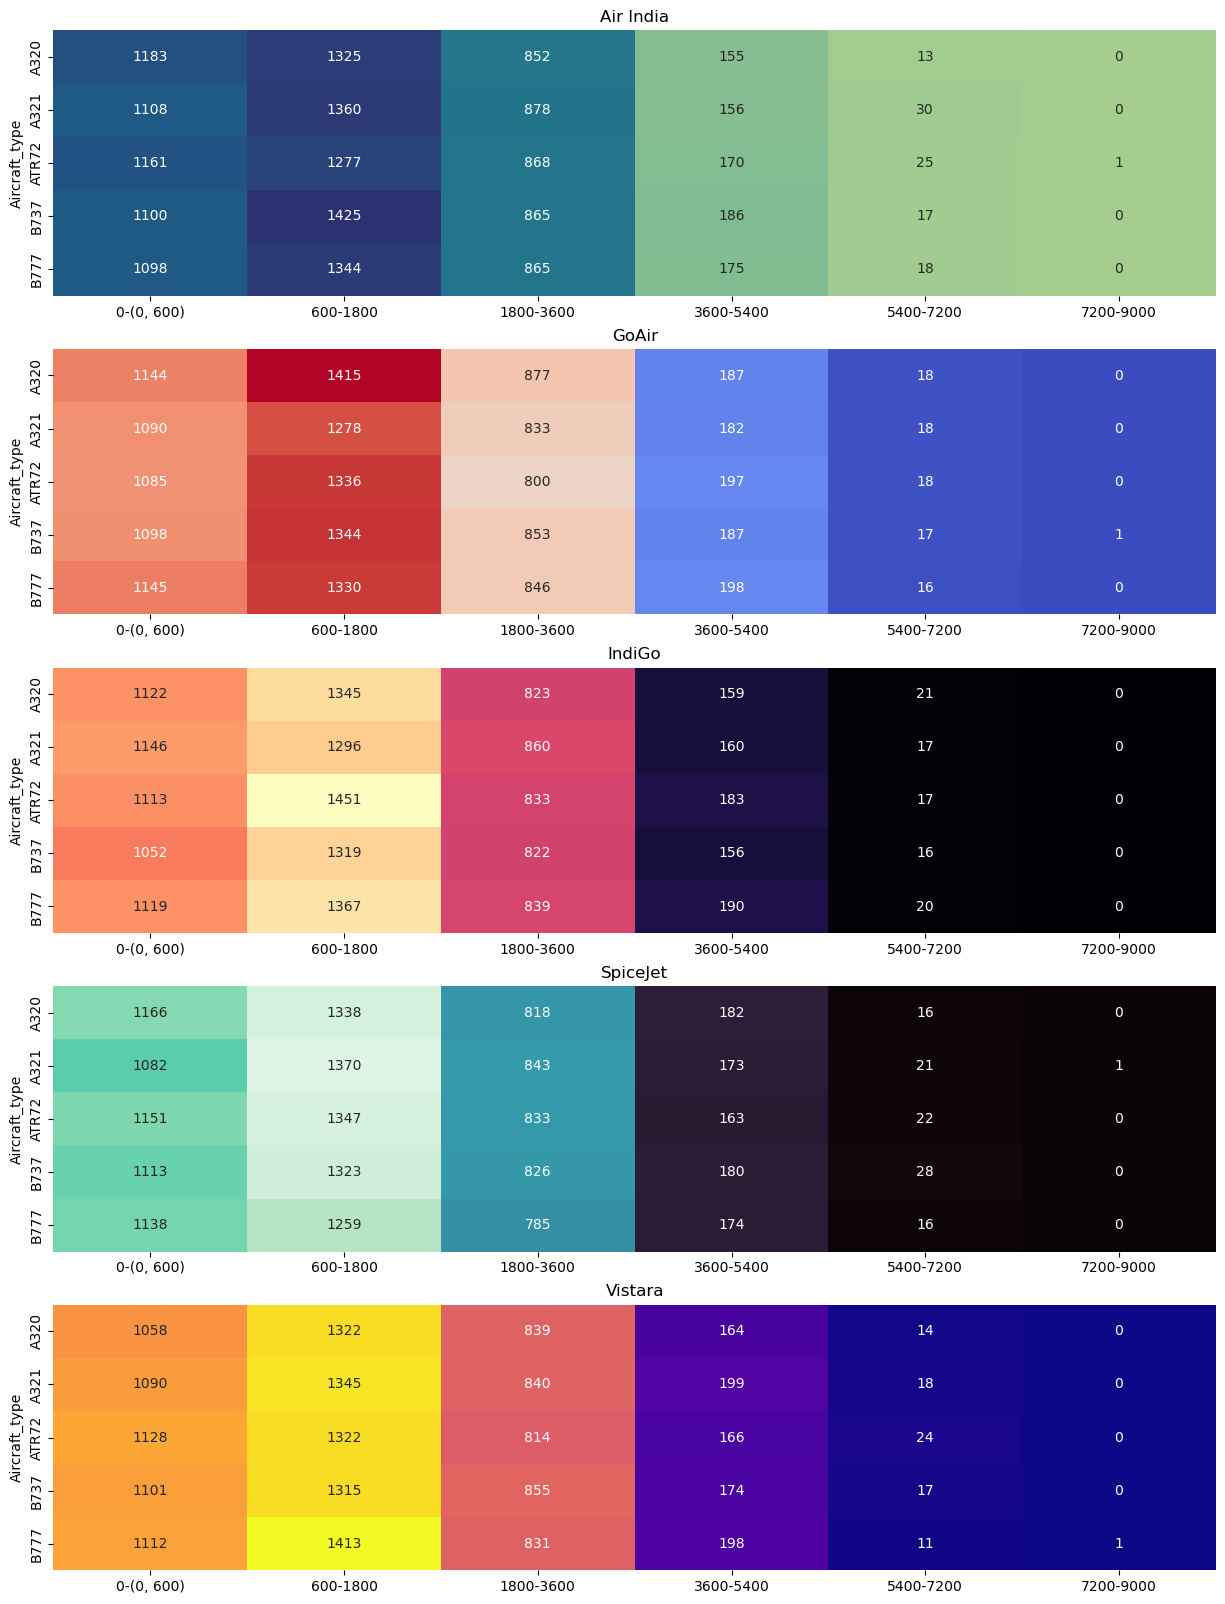

In [62]:
figure,axes=plt.subplots(len(AADC.Airline.unique()),1,figsize=(15,20))
colour=["crest","coolwarm","magma","mako","plasma"]
for aind,airline in enumerate(AADC["Airline"].unique()):
    ax=axes[aind]
    data=AADC[AADC["Airline"]==airline].drop("Airline",axis=1).set_index("Aircraft_type")
    sns.heatmap(data,ax=ax,annot=True,fmt="d",cmap=colour[aind],cbar=False)
    ax.set_title(airline)
    

In [63]:
df["Date"].dt.month_name()

0             June
1        September
2         November
3             June
4          October
           ...    
99995     December
99996         July
99997       August
99998         July
99999          May
Name: Date, Length: 100000, dtype: object

In [64]:
#airline aircraft daily departed flight count 
AADDFC=df[df["Distance_km"]!=0].assign(month=df["Date"].dt.month,
                                day=df["Date"].dt.day).groupby(["Airline",
                                                                "Aircraft_Type",
                                                                "month",
                                                                "day"]).agg(flight_count_departed=("Flight_Number","count")).reset_index()

In [65]:
def month_name(x):
    dic={
        1:"Jnaurary",
        2:"Fabirary",
        3:"March",
        4:"April",
        5:"May",
        6:"June",
        7:"July",
        8:"August",
        9:"September",
        10:"October",
        11:"November",
        12:"December"
    }
    return dic[x]if x in dic else None


In [66]:
AADDFC

,Airline,Aircraft_Type,month,day,flight_count_departed
0,Air India,A320,1,1,7
1,Air India,A320,1,2,11
2,Air India,A320,1,3,11
3,Air India,A320,1,4,7
4,Air India,A320,1,5,12
...,...,...,...,...,...
9117,Vistara,B777,12,27,11
9118,Vistara,B777,12,28,10
9119,Vistara,B777,12,29,9
9120,Vistara,B777,12,30,10


In [67]:
x=AADDFC[AADDFC["Airline"]=="Air India"]
y=x[x["Aircraft_Type"]=="A320"].pivot_table(index="month",columns="day",values="flight_count_departed",fill_value=0).astype("int")
y.index=[month_name(i) for i in y.index]
y

day,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
Jnaurary,7,11,11,7,12,9,13,12,16,11,...,8,7,13,8,9,10,7,11,13,7
Fabirary,11,7,13,4,13,13,8,9,6,6,...,8,12,9,9,9,14,9,0,0,0
March,7,5,8,5,12,14,14,7,10,10,...,9,8,12,10,4,9,10,10,13,8
April,11,8,5,5,16,9,11,9,14,8,...,7,13,10,5,8,21,14,10,11,0
May,7,5,14,11,13,5,11,6,7,6,...,8,9,12,9,9,7,14,8,10,7
June,6,8,8,16,15,6,11,6,8,10,...,12,3,10,12,9,23,13,9,7,0
July,9,11,10,11,11,9,8,6,15,9,...,14,10,5,12,19,8,9,11,9,10
August,16,7,11,7,5,9,9,7,13,12,...,12,8,5,12,11,8,9,8,18,8
September,12,12,8,13,8,10,19,6,6,8,...,9,6,9,9,8,7,14,6,13,0
October,19,7,7,10,12,9,10,6,9,9,...,18,11,9,4,10,8,8,12,6,7


In [68]:
air=AADDFC.Airline.unique()
figure, axes=plt.subplots(len(air),len(AADDFC.Aircraft_Type.unique()),figsize=(200,100))
color_map=["crest","coolwarm","magma","mako","plasma"]
for aind,airline in enumerate(air):
    adata=AADDFC[AADDFC["Airline"]==airline]
    for atind,atype in enumerate(AADDFC.Aircraft_Type.unique()):
        axs=axes[aind][atind]
        atdata=adata[adata["Aircraft_Type"]==atype].pivot_table(index="month",columns="day",values="flight_count_departed",fill_value=0).astype("int")
        atdata.index=[month_name(i) for i in atdata.index]
        sns.heatmap(atdata,ax=axs,annot=True,fmt="d",annot_kws={"fontsize":35},cmap=color_map[atind],cbar=False,linecolor="white",linewidth=5)
        axs.set_title(f"{airline} {atype}",fontsize=50)
plt.show()
        
